In [ ]:
!pip install -q torch torchvision transformers datasets openai matplotlib numpy pillow

In [2]:
import base64
import os
import re
import time
import warnings
from io import BytesIO
from itertools import islice

import datasets
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from datasets import load_dataset
from openai import OpenAI
from PIL import Image
from torchvision.ops import box_iou
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
os.environ["OPENAI_API_KEY"] = ""

client = OpenAI()
MODEL = "gpt-5-mini"
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "Qwen/Qwen3-VL-2B-Instruct"
CHART_NAME = "HuggingFaceM4/ChartQA"
REFCOCO_NAME = "lmms-lab/RefCOCO"
SEED = 0
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# Reasoning and Inference in VLMs

Two inference-time choices decide what a deployed VLM can do with an image beyond describing it.
**How long it thinks**: a reasoning model can spend hidden tokens reading values off a chart and
doing the arithmetic before it answers, at a price in latency and tokens that should only be
paid where it changes the answer. **What it outputs**: a model post-trained for grounding writes
box coordinates as ordinary text tokens, so "where is it?" becomes a parsing and scoring
problem rather than a new architecture.

| Question | Knob | Measured with |
|---|---|---|
| When does thinking pay off? | `reasoning.effort` = minimal / low / high | ChartQA relaxed accuracy vs reasoning tokens |
| Can the LM head localise? | grounding prompt + parser | RefCOCO IoU, grounding-tuned 2B VLM vs a general API model |

---

# 1) Thinking Over Charts

"What is the value of the largest bar?" needs one reading of the chart. "How much did the top
two categories change between 2014 and 2019?" needs four readings and two subtractions, and a
direct answer gives the model nowhere to put the intermediate work. Reasoning models spend
hidden tokens on that work first; the cost is visible in `usage.output_tokens_details`.

The difficulty sits in the image, not in the wording, so a keyword rule cannot tell which
questions need it. The only reliable signal is to measure: run the same questions at each
effort level and see which answers change.

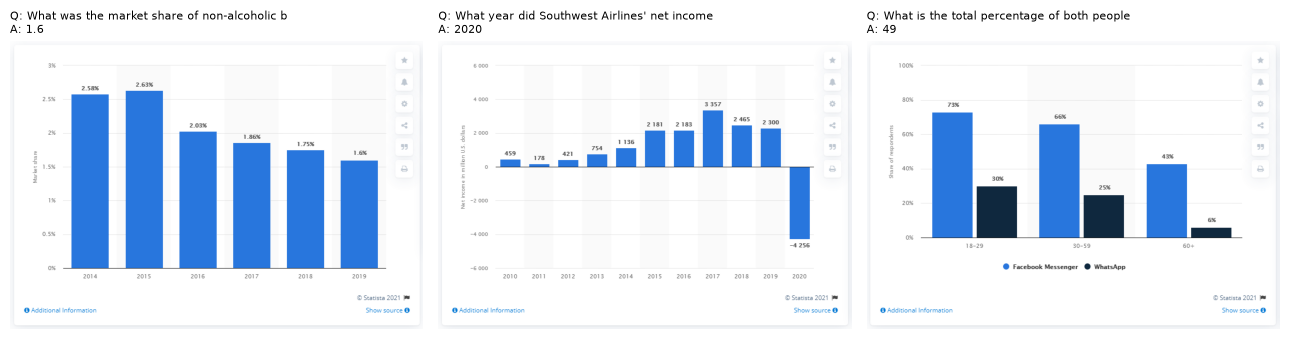

In [3]:
def load_chartqa(split: str = "val", n: int = 16) -> list[dict]:
    """(chart, question, answer) triples from ChartQA."""
    rows = load_dataset(CHART_NAME, split=split).shuffle(seed=SEED).select(range(n))
    return [
        {
            "image": r["image"].convert("RGB"),
            "question": r["query"],
            "answer": r["label"][0],
        }
        for r in rows
    ]


def encode_image(image: Image.Image, max_side: int = 768) -> str:
    """PIL image -> PNG data URL, downscaled first (the API bills image tokens by
    area).
    """
    img = image.copy()
    img.thumbnail((max_side, max_side))
    buf = BytesIO()
    img.save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def normalize(s: str) -> str:
    """Lower-case and drop whitespace, %, $, commas and a trailing period."""
    return re.sub(r"[\s%$,]", "", s.strip().lower().rstrip(".").strip())


def relaxed_match(pred: str, gold: str, tol: float = 0.05) -> bool:
    """ChartQA relaxed accuracy: string match, or numeric match within 5%."""
    p, g = normalize(pred), normalize(gold)
    if p == g:
        return True
    try:
        pn = float(re.sub(r"[^0-9.\-]", "", p)) if re.search(r"\d", p) else None
        gn = float(re.sub(r"[^0-9.\-]", "", g)) if re.search(r"\d", g) else None
    except ValueError:
        return False
    return pn is not None and gn is not None and abs(pn - gn) <= tol * abs(gn)


SAMPLES = load_chartqa(n=16)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SAMPLES[:3]):
    ax.imshow(s["image"])
    ax.axis("off")
    ax.set_title(f"Q: {s['question'][:44]}\nA: {s['answer']}", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

In [4]:
ANSWER_HINT = "Answer the question using a single word or phrase."


def ask_chart(sample: dict, effort: str) -> dict:
    """One image + question call; the answer and what the reasoning cost."""
    start = time.time()
    resp = client.responses.create(
        model=MODEL,
        reasoning={"effort": effort},
        max_output_tokens=2048,
        input=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "input_text",
                        "text": f"{sample['question']}\n{ANSWER_HINT}",
                    },
                    {
                        "type": "input_image",
                        "image_url": encode_image(sample["image"]),
                        "detail": "auto",
                    },
                ],
            }
        ],
    )
    return {
        "answer": resp.output_text.strip(),
        "reasoning_tokens": resp.usage.output_tokens_details.reasoning_tokens,
        "output_tokens": resp.usage.output_tokens,
        "seconds": time.time() - start,
    }


demo = SAMPLES[0]
print(f"Q: {demo['question']}\ngold: {demo['answer']}")
for effort in ("minimal", "high"):
    r = ask_chart(demo, effort)
    visible = r["output_tokens"] - r["reasoning_tokens"]
    print(
        f"  effort={effort:<8} answer={r['answer'][:30]!r} reasoning "
        f"{r['reasoning_tokens']:>4} tok | visible {visible:>3} tok | "
        f"{r['seconds']:.1f} s"
    )

Q: What was the market share of non-alcoholic beer in Italy in 2019?
gold: 1.6


  effort=minimal  answer='1.6%' reasoning    0 tok | visible  22 tok | 3.6 s


  effort=high     answer='1.6%' reasoning  256 tok | visible  10 tok | 3.5 s


effort=minimal  relaxed  62.5% |     0 reasoning tok/q |  1.8 s/q


effort=low      relaxed  62.5% |    32 reasoning tok/q |  2.3 s/q


effort=high     relaxed  68.8% |   372 reasoning tok/q |  5.7 s/q

rescued by high effort (2):
  How much was eBay's net revenue in the most recent fiscal year?
  What is the difference between Carex and Palmolive?
broken by high effort (1): ['The bar chart covers how many years?']


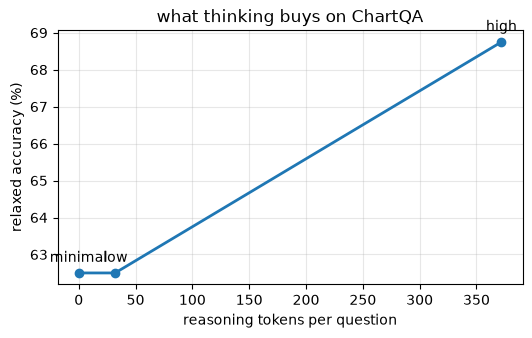

In [5]:
EFFORTS = ["minimal", "low", "high"]
results = {}
for effort in EFFORTS:
    runs = [ask_chart(s, effort) for s in SAMPLES]
    correct = [relaxed_match(r["answer"], s["answer"]) for r, s in zip(runs, SAMPLES)]
    results[effort] = {
        "accuracy": float(np.mean(correct)),
        "reasoning": float(np.mean([r["reasoning_tokens"] for r in runs])),
        "seconds": float(np.mean([r["seconds"] for r in runs])),
        "correct": correct,
    }
    print(
        f"effort={effort:<8} relaxed {results[effort]['accuracy']:6.1%} | "
        f"{results[effort]['reasoning']:5.0f} reasoning tok/q | "
        f"{results[effort]['seconds']:4.1f} s/q"
    )

lo, hi = results["minimal"]["correct"], results["high"]["correct"]
rescued = [
    SAMPLES[i]["question"] for i, (a, b) in enumerate(zip(lo, hi)) if b and not a
]
broken = [SAMPLES[i]["question"] for i, (a, b) in enumerate(zip(lo, hi)) if a and not b]
print(f"\nrescued by high effort ({len(rescued)}):")
for q in rescued:
    print(f"  {q[:80]}")
print(f"broken by high effort ({len(broken)}): {[q[:60] for q in broken]}")

fig, ax = plt.subplots(figsize=(6, 3.3))
x = [results[e]["reasoning"] for e in EFFORTS]
y = [results[e]["accuracy"] * 100 for e in EFFORTS]
ax.plot(x, y, "o-", lw=2)
for e, xi, yi in zip(EFFORTS, x, y):
    ax.annotate(e, (xi, yi), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set(
    xlabel="reasoning tokens per question",
    ylabel="relaxed accuracy (%)",
    title="what thinking buys on ChartQA",
)
ax.grid(alpha=0.3)
plt.show()

The questions that flip from wrong to right are the routing signal. In production they become
labels for a cheap router (a small classifier on the image and question, or the model's own
one-token "does this need work?" judgement), so that only that fraction of traffic pays the
reasoning cost.

---

# 2) Visual Grounding: Boxes as Text

There is no box head. Qwen2.5-VL, Qwen3-VL, Kosmos-2, Florence-2 and PaliGemma all write
coordinates with the ordinary LM head: as numbers on a resolution-independent 0–1000 grid
(Qwen3-VL), absolute pixels (Qwen2.5-VL) or dedicated `<loc_k>` tokens (Kosmos-2, PaliGemma).
Grounding is learned in post-training from box-annotated data, so the client's job is a fixed
prompt, a parser and a metric.

**RefCOCO** gives a referring expression ("child sitting on woman's lap") and one gold box per
image; a prediction counts as correct at IoU ≥ 0.5 (Acc@0.5). Two models are compared on the
same 16 expressions: Qwen3-VL-2B-Instruct, a 2 B open VLM post-trained for grounding and run
locally, and `gpt-5-mini`, a much larger general model that was not.

In [6]:
def load_refcoco(n: int = 16) -> list[dict]:
    """Referring expression + gold box in [0, 1] xyxy (RefCOCO stores pixel xywh)."""
    out = []
    for r in islice(load_dataset(REFCOCO_NAME, split="val", streaming=True), n):
        w, h = r["image"].size
        x, y, bw, bh = r["bbox"]
        out.append(
            {
                "image": r["image"].convert("RGB"),
                "expression": r["answer"][0],
                "gold": [x / w, y / h, (x + bw) / w, (y + bh) / h],
            }
        )
    return out


def parse_box(text: str) -> list[float] | None:
    """First [x1, y1, x2, y2] list in the reply, read on the 0-1000 grid -> [0, 1]
    xyxy, or None.
    """
    # numbers inside the first bracketed list ("bbox_2d" itself contains a digit)
    match = re.search(r"\[([^\[\]]+)\]", text)
    nums = (
        [float(v) for v in re.findall(r"-?\d+(?:\.\d+)?", match.group(1))[:4]]
        if match
        else []
    )
    if len(nums) < 4:
        return None
    box = [v / 1000 for v in nums]
    valid = all(0 <= v <= 1 for v in box) and box[0] < box[2] and box[1] < box[3]
    return box if valid else None


REF_SAMPLES = load_refcoco(16)
PROMPT = (
    'Locate "{expr}" in the image. '
    'Reply with JSON {{"bbox_2d": [x1, y1, x2, y2]}} on a 0-1000 grid.'
)
print(PROMPT.format(expr=REF_SAMPLES[0]["expression"]))
print("parse:", parse_box('[{"bbox_2d": [102, 340, 488, 997], "label": "girl"}]'))

Locate "bowl behind the others can only see part" in the image. Reply with JSON {"bbox_2d": [x1, y1, x2, y2]} on a 0-1000 grid.
parse: [0.102, 0.34, 0.488, 0.997]


In [7]:
processor = AutoProcessor.from_pretrained(MODEL_NAME)
vlm = (
    Qwen3VLForConditionalGeneration.from_pretrained(MODEL_NAME, dtype=torch.bfloat16)
    .to(DEVICE)
    .eval()
)


@torch.no_grad()
def locate_local(sample: dict) -> tuple[list[float] | None, str]:
    """Qwen3-VL grounding: (box or None, raw reply)."""
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": sample["image"]},
                {"type": "text", "text": PROMPT.format(expr=sample["expression"])},
            ],
        }
    ]
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(DEVICE)
    out = vlm.generate(**inputs, max_new_tokens=48, do_sample=False)
    reply = processor.decode(
        out[0, inputs["input_ids"].shape[1] :], skip_special_tokens=True
    )
    return parse_box(reply), reply

In [8]:
def locate_api(sample: dict) -> tuple[list[float] | None, str]:
    """gpt-5-mini grounding with the same prompt."""
    resp = client.responses.create(
        model=MODEL,
        reasoning={"effort": "low"},
        max_output_tokens=2048,
        input=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "input_text",
                        "text": PROMPT.format(expr=sample["expression"]),
                    },
                    {
                        "type": "input_image",
                        "image_url": encode_image(sample["image"], 1024),
                        "detail": "high",
                    },
                ],
            }
        ],
    )
    return parse_box(resp.output_text), resp.output_text


def iou(pred: list[float] | None, gold: list[float]) -> float:
    """IoU of two [0, 1] xyxy boxes; 0 for an unparseable prediction."""
    return (
        0.0
        if pred is None
        else box_iou(torch.tensor([pred]), torch.tensor([gold])).item()
    )


scores = {}
for name, locate in [
    ("Qwen3-VL-2B (grounding-tuned)", locate_local),
    ("gpt-5-mini (general)", locate_api),
]:
    start = time.time()
    preds = [locate(s) for s in REF_SAMPLES]
    ious = [iou(p, s["gold"]) for (p, _), s in zip(preds, REF_SAMPLES)]
    scores[name] = (preds, ious)
    print(
        f"{name:<32} mean IoU {np.mean(ious):.3f} | Acc@0.5 "
        f"{np.mean([v >= 0.5 for v in ious]):.0%} | "
        f"unparseable {sum(p is None for p, _ in preds)} | "
        f"{(time.time() - start) / len(REF_SAMPLES):.1f} s/expr"
    )
print(
    "example raw replies:",
    repr(scores["Qwen3-VL-2B (grounding-tuned)"][0][0][1][:80]),
    "|",
    repr(scores["gpt-5-mini (general)"][0][0][1][:80]),
)

Qwen3-VL-2B (grounding-tuned)    mean IoU 0.871 | Acc@0.5 94% | unparseable 0 | 2.0 s/expr


gpt-5-mini (general)             mean IoU 0.440 | Acc@0.5 50% | unparseable 0 | 4.0 s/expr
example raw replies: '```json\n{\n  "bbox_2d": [183, 0, 720, 424]\n}\n```' | '{"bbox_2d": [328, 23, 734, 351]}'


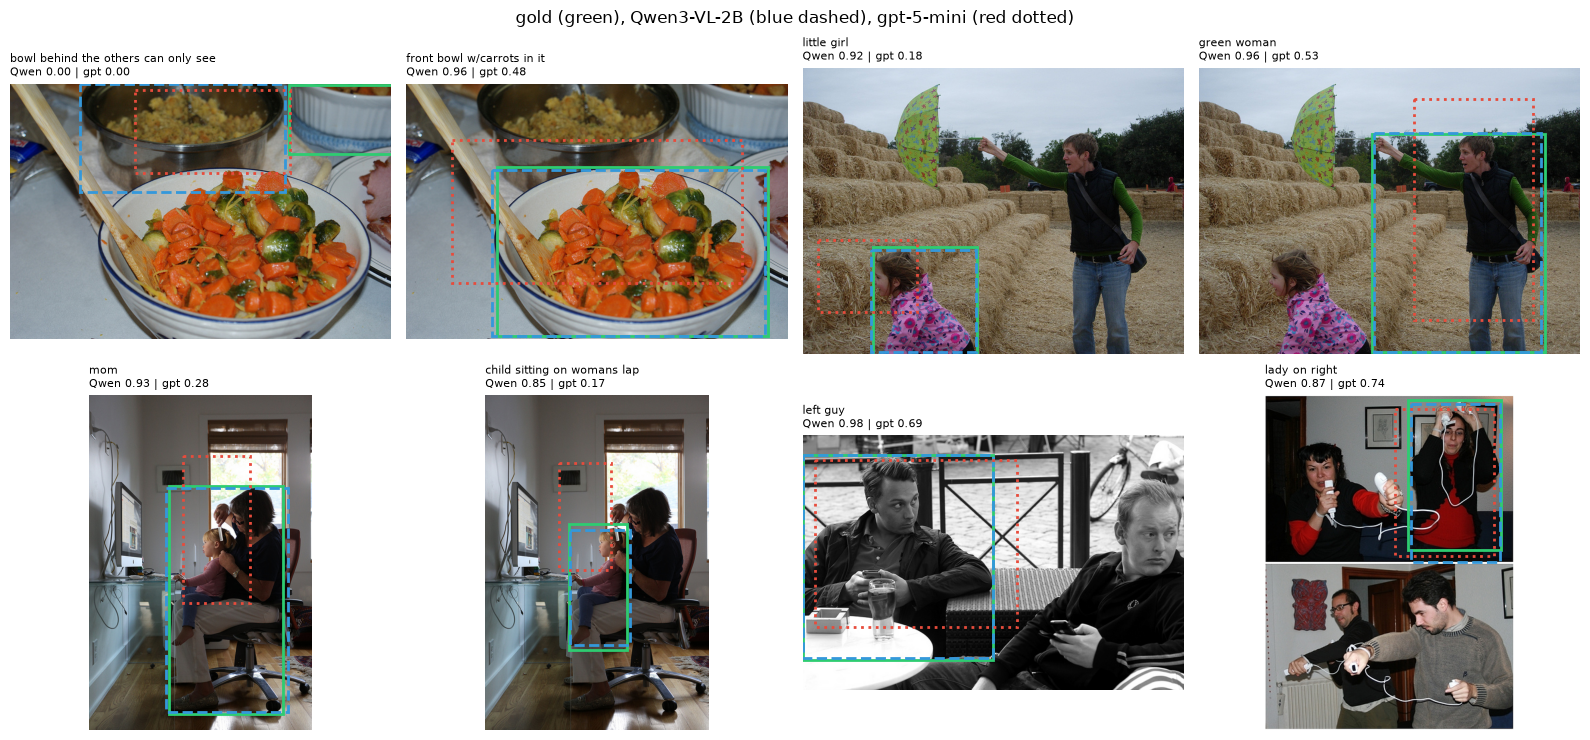

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
local_preds, local_ious = scores["Qwen3-VL-2B (grounding-tuned)"]
api_preds, api_ious = scores["gpt-5-mini (general)"]
for ax, s, (lp, _), (ap, _), li, ai in zip(
    axes.flat, REF_SAMPLES, local_preds, api_preds, local_ious, api_ious
):
    w, h = s["image"].size
    ax.imshow(s["image"])
    for box, color, style in [
        (s["gold"], "#2ECC71", "-"),
        (lp, "#3498DB", "--"),
        (ap, "#E74C3C", ":"),
    ]:
        if box is not None:
            ax.add_patch(
                patches.Rectangle(
                    (box[0] * w, box[1] * h),
                    (box[2] - box[0]) * w,
                    (box[3] - box[1]) * h,
                    lw=2,
                    ec=color,
                    ls=style,
                    fc="none",
                )
            )
    ax.set_title(
        f"{s['expression'][:36]}\nQwen {li:.2f} | gpt {ai:.2f}", fontsize=8, loc="left"
    )
    ax.axis("off")
plt.suptitle("gold (green), Qwen3-VL-2B (blue dashed), gpt-5-mini (red dotted)")
plt.tight_layout()
plt.show()

# 3) Practical Notes

- **Reasoning budget.** Effort levels change latency several-fold and output cost with it;
  answers that are a single read-off do not improve, multi-step arithmetic over a chart does.
  Route rather than raise effort globally; cap `max_output_tokens` so a runaway chain cannot
  eat the budget (a truncated reasoning trace returns an empty answer).
- **Image tokens.** Hosted APIs bill images by area or tile count; downscale to the smallest
  size where the labels stay legible. Local VLMs have the same trade in visual tokens.
- **Grounding format.** Use the exact output convention the model was post-trained with
  (Qwen3-VL: JSON `bbox_2d` on a 0–1000 grid; Qwen2.5-VL: absolute pixels of the resized
  input). A mismatched convention produces confident, systematically shifted boxes.
- **Validation.** Parse defensively, reject boxes outside the image or with $x_1 \ge x_2$, and
  count unparseable replies as misses so the metric reflects what a downstream system sees.
- **Production grounding** for many objects per image is still faster with a detector
  (OWLv2, Grounding DINO, SAM 3); VLM grounding wins on long, relational referring expressions.

# 4) Conclusion

| Capability | Mechanism | What the run showed |
|---|---|---|
| Thinking | hidden reasoning tokens before the answer | gains concentrate on multi-step chart questions; cost grows with effort |
| Routing | measure flips per question, then learn a router | a word list cannot predict which questions flip |
| Grounding | coordinates written by the LM head, parsed client-side | a small grounding-tuned VLM beats a large general model on RefCOCO IoU |